# Ejercicio 4 — ¿Es posible reconstruir la imagen de manera única?

**Etiqueta de uso de IA:** *Asistencia para destrabar / corregir*.

Ya sabemos escribir la adquisición como $b = Ax$ con $A \in \mathbb{R}^{m\times 64}$. La
pregunta ahora es si esas mediciones **alcanzan** para recuperar la imagen. La respuesta es
puramente algebraica y depende del **rango** y del **espacio nulo** de $A$: agregar más
rayos no sirve de nada si las nuevas filas son combinación lineal de las anteriores.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("figuras", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "image.cmap": "gray"})


def guardar(fig, nombre):
    # Guarda la figura en figuras/, como pide el formato de entrega.
    fig.savefig(os.path.join("figuras", nombre + ".png"), bbox_inches="tight", dpi=150)


X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = 8
x_fantoma = X_fantoma.reshape(-1)   # k = i*n + j


def mascara_rayo(n, direccion, s):
    # M[i,j] = 1  <=>  alpha*i + beta*j == s
    alpha, beta = direccion
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    return (alpha * i + beta * j == s).astype(float)


def matriz_proyeccion(n, direcciones):
    # Devuelve A (m x n^2) y la lista de pares ((alpha, beta), s) de cada fila.
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    filas, info = [], []
    for direccion in direcciones:
        alpha, beta = direccion
        valores_s = np.unique(alpha * i + beta * j)   # np.unique ya devuelve ordenado
        for s in valores_s:
            filas.append(mascara_rayo(n, direccion, int(s)).reshape(-1))
            info.append((direccion, int(s)))
    return np.array(filas, dtype=float), info


D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]


## a) Condición de unicidad: teorema de rango y nulidad

Sea $A \in \mathbb{R}^{m\times 64}$. Supongamos que dos imágenes $x_1 \ne x_2$ producen las
mismas mediciones, $Ax_1 = Ax_2$. Por linealidad,

$$A(x_1 - x_2) = 0 \quad\Longrightarrow\quad v := x_1 - x_2 \in \operatorname{Nul}(A),
\qquad v \neq 0 .$$

Recíprocamente, si existe $v \neq 0$ con $Av = 0$, entonces para cualquier solución $x$ el
vector $x + \lambda v$ es **otra** solución del mismo sistema, para todo $\lambda$: hay
infinitas imágenes con mediciones idénticas. Por lo tanto:

> La reconstrucción es única $\iff \operatorname{Nul}(A) = \{0\} \iff$ las columnas de $A$
> son linealmente independientes.

El **teorema de rango y nulidad**, aplicado a $A$ como transformación lineal
$\mathbb{R}^{64}\to\mathbb{R}^{m}$, dice

$$\operatorname{rango}(A) + \dim\!\big(\operatorname{Nul}(A)\big) = 64
\qquad\text{(cantidad de columnas = cantidad de píxeles).}$$

Entonces $\dim(\operatorname{Nul}(A)) = 0$ equivale a

$$\boxed{\operatorname{rango}(A) = 64 = n^2}$$

es decir, $A$ debe tener **rango columna completo**. Consecuencias prácticas:

- Es necesario que $m \ge 64$, porque $\operatorname{rango}(A) \le \min(m, 64)$. Pero
  **no alcanza**: se pueden tener cientos de rayos y aun así rango deficiente si las filas
  son redundantes (por ejemplo, la suma de todas las filas de la dirección $(1,0)$ es igual
  a la suma de todas las de $(0,1)$: ambas dan la suma total de la imagen).
- La diferencia $m - \operatorname{rango}(A)$ mide cuántas mediciones son **redundantes**:
  no aportan ecuaciones independientes.
- Cuando $\dim(\operatorname{Nul}(A)) = d > 0$, el conjunto de soluciones es un subespacio
  afín de dimensión $d$: $\{x_0 + v : v \in \operatorname{Nul}(A)\}$. Los elementos de
  $\operatorname{Nul}(A)$ son "imágenes fantasma" completamente invisibles para el escáner.

## b) Las matrices $A_2$, $A_4$ y $A_7$

Construimos las tres matrices con los conjuntos de direcciones

$$D_2 = \{(1,0),(0,1)\},\qquad
D_4 = D_2 \cup \{(1,1),(1,-1)\},\qquad
D_7 = D_4 \cup \{(2,1),(1,2),(3,1)\}.$$

In [2]:
A2, info2 = matriz_proyeccion(n, D2)
A4, info4 = matriz_proyeccion(n, D4)
A7, info7 = matriz_proyeccion(n, D7)

matrices = {2: A2, 4: A4, 7: A7}

filas = []
for k, A in matrices.items():
    m = A.shape[0]
    rango = np.linalg.matrix_rank(A)
    filas.append((k, A.shape, m, rango, 64 - rango, m - rango, rango == 64))

enc = f"{'k':>2} {'dim(A_k)':>12} {'m':>5} {'rango':>6} {'dim Nul':>8} {'m - rango':>10} {'¿única?':>9}"
print(enc)
print("-" * len(enc))
for k, forma, m, rango, nul, red, unica in filas:
    print(f"{k:>2} {str(forma):>12} {m:>5} {rango:>6} {nul:>8} {red:>10} "
          f"{'SÍ' if unica else 'NO':>9}")

 k     dim(A_k)     m  rango  dim Nul  m - rango   ¿única?
----------------------------------------------------------
 2     (16, 64)    16     15       49          1        NO
 4     (46, 64)    46     39       25          7        NO
 7    (119, 64)   119     64        0         55        SÍ


In [3]:
# Cuántos rayos aporta cada dirección, para entender de dónde salen las filas.
print(f"{'dirección':>12} {'#rayos':>8}")
print("-" * 21)
for d in D7:
    a, be = d
    cuantos = len(np.unique(a * np.arange(n).reshape(n, 1) + be * np.arange(n).reshape(1, n)))
    print(f"{str(d):>12} {cuantos:>8}")
print(f"{'TOTAL D7':>12} {A7.shape[0]:>8}")

   dirección   #rayos
---------------------
      (1, 0)        8
      (0, 1)        8
      (1, 1)       15
     (1, -1)       15
      (2, 1)       22
      (1, 2)       22
      (3, 1)       29
    TOTAL D7      119


### Lectura de la tabla

- **$A_2 \in \mathbb{R}^{16\times 64}$, rango 15.** Con $m = 16 \ll 64$ era imposible tener
  rango completo. Además el rango es $15$, no $16$: hay **una** medición redundante, y se
  entiende exactamente cuál. La suma de las $8$ mediciones de fila y la suma de las $8$ de
  columna dan ambas la suma total de la imagen, o sea
  $\sum_{r<8} a_r = \sum_{r\ge 8} a_r = \mathbf{1}$, una relación lineal entre las filas.
  El espacio nulo tiene dimensión $49$: quedan $49$ grados de libertad sin determinar.

- **$A_4 \in \mathbb{R}^{46\times 64}$, rango 39.** Sumar las dos familias de diagonales
  agrega $30$ ecuaciones, pero sólo $24$ son nuevas: hay $7$ redundancias
  ($46 - 39$). Todavía $m < 64$, así que la unicidad sigue siendo imposible; el espacio nulo
  bajó de $49$ a $25$ dimensiones.

- **$A_7 \in \mathbb{R}^{119\times 64}$, rango 64.** Ahora sí $\operatorname{rango} = n^2$:
  el espacio nulo es trivial y la imagen queda **determinada de manera única**. Nótese que
  hay $119 - 64 = 55$ mediciones redundantes: el sistema es fuertemente sobredeterminado.
  Esa redundancia no es un desperdicio — cuando aparezca ruido (Ejercicio 6) es justamente
  lo que permite promediar errores mediante mínimos cuadrados.

In [4]:
# Verificación explícita de la redundancia de A2: suma de filas = suma de columnas.
combinacion = A2[:8].sum(axis=0) - A2[8:].sum(axis=0)
print("|| suma(filas 0..7) - suma(filas 8..15) || =", np.linalg.norm(combinacion))
print("=> las 16 filas de A2 son linealmente dependientes, por eso rango(A2) = 15.")

|| suma(filas 0..7) - suma(filas 8..15) || = 0.0
=> las 16 filas de A2 son linealmente dependientes, por eso rango(A2) = 15.


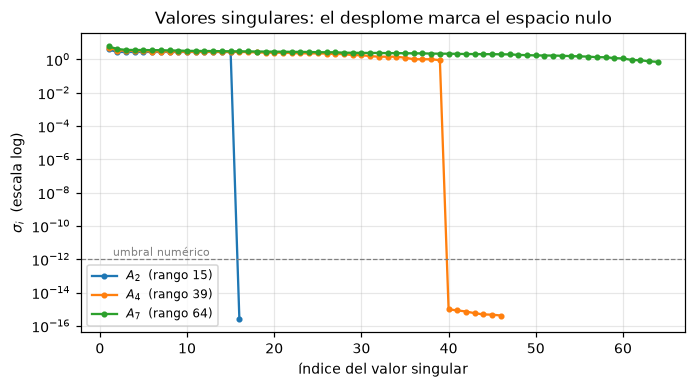

In [5]:
# Valores singulares: muestran el "salto" al espacio nulo.
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for k, A in matrices.items():
    sv = np.linalg.svd(A, compute_uv=False)
    sv_padded = np.full(64, np.nan)
    sv_padded[:len(sv)] = sv[:64]
    ax.semilogy(np.arange(1, 65), np.maximum(sv_padded, 1e-18), "o-", ms=3,
                label=f"$A_{{{k}}}$  (rango {np.linalg.matrix_rank(A)})")
ax.axhline(1e-12, color="gray", ls="--", lw=0.8)
ax.text(1.5, 1.6e-12, "umbral numérico", fontsize=7, color="gray")
ax.set_xlabel("índice del valor singular")
ax.set_ylabel(r"$\sigma_i$  (escala log)")
ax.set_title("Valores singulares: el desplome marca el espacio nulo")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
guardar(fig, "ejercicio_04b_valores_singulares")
plt.show()

El gráfico hace visible el teorema de rango y nulidad: los valores singulares de $A_2$ se
desploman a cero numérico a partir del índice $16$, los de $A_4$ a partir del $40$, y los de
$A_7$ se mantienen todos por encima del umbral hasta el $64$. La cantidad de valores
singulares no nulos **es** el rango, y las direcciones asociadas a los valores singulares
nulos generan el espacio nulo.

## c) Un vector del espacio nulo de $A_4$ mediante SVD

La descomposición $A_4 = U\Sigma V^{T}$ nos da una base ortonormal $\{v_i\}$ (columnas de
$V$, filas de `Vt`). Como $A_4 v_i = \sigma_i u_i$, los $v_i$ asociados a $\sigma_i \approx 0$
generan (numéricamente) el espacio nulo. Tomamos el último, el de menor valor singular.

In [6]:
U, S, Vt = np.linalg.svd(A4)

print("A4:", A4.shape, "  rango:", np.linalg.matrix_rank(A4))
print("valores singulares más chicos:", np.array2string(S[-6:], precision=3))
print()

v = Vt[-1]                       # última fila de V^T = último vector singular derecho
v = v / np.linalg.norm(v)        # ya viene normalizado, lo dejamos explícito

print("||v||        =", np.linalg.norm(v))
print("||A4 v||     =", np.linalg.norm(A4 @ v), "   (≈ 0)")
print("||A4||_2      =", np.linalg.norm(A4, 2), "  (norma espectral, para comparar)")
print("=> A4 v ≈ 0 hasta la precisión de máquina: v ∈ Nul(A4).")

A4: (46, 64)   rango: 39
valores singulares más chicos: [8.620e-16 7.274e-16 6.169e-16 5.114e-16 4.935e-16 4.695e-16]

||v||        = 1.0000000000000002
||A4 v||     = 1.2060761651756089e-15    (≈ 0)
||A4||_2      = 5.18999249866714   (norma espectral, para comparar)
=> A4 v ≈ 0 hasta la precisión de máquina: v ∈ Nul(A4).


In [7]:
b4 = A4 @ x_fantoma

alfa = 0.4 * np.linalg.norm(x_fantoma)   # amplitud de la perturbación
x_alt = x_fantoma + alfa * v
b4_alt = A4 @ x_alt

print(f"alfa = {alfa:.4f}")
print("||x_alt - x_fantoma||               =", np.linalg.norm(x_alt - x_fantoma))
print("en relación a ||x_fantoma||         =",
      np.linalg.norm(x_alt - x_fantoma) / np.linalg.norm(x_fantoma))
print()
print("||b4||                              =", np.linalg.norm(b4))
print("||A4 x_alt - b4||                   =", np.linalg.norm(b4_alt - b4))
print("error relativo en las mediciones    =",
      np.linalg.norm(b4_alt - b4) / np.linalg.norm(b4))
print()
print("¿mediciones indistinguibles?", np.allclose(b4_alt, b4))

alfa = 1.0143
||x_alt - x_fantoma||               = 1.0142977866484777
en relación a ||x_fantoma||         = 0.40000000000000013

||b4||                              = 10.358571330062848
||A4 x_alt - b4||                   = 1.174943101032943e-15
error relativo en las mediciones    = 1.134271381250231e-16

¿mediciones indistinguibles? True


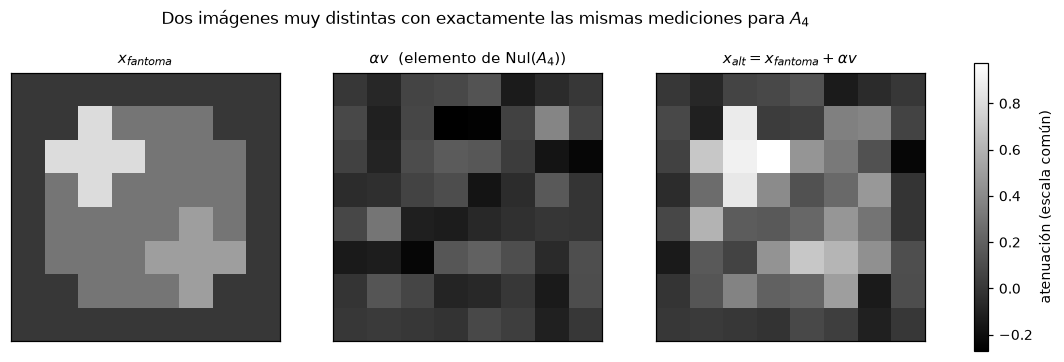

In [8]:
V_img = (alfa * v).reshape(n, n)
X_alt = x_alt.reshape(n, n)

vmin = min(X_fantoma.min(), X_alt.min(), V_img.min())
vmax = max(X_fantoma.max(), X_alt.max(), V_img.max())

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4))
titulos = [r"$x_{fantoma}$",
           r"$\alpha v$  (elemento de $\mathrm{Nul}(A_4)$)",
           r"$x_{alt} = x_{fantoma} + \alpha v$"]
for ax, M, t in zip(axes, [X_fantoma, V_img, X_alt], titulos):
    im = ax.imshow(M, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(t, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.018, label="atenuación (escala común)")
fig.suptitle("Dos imágenes muy distintas con exactamente las mismas mediciones para $A_4$",
             y=1.02)
guardar(fig, "ejercicio_04c_espacio_nulo")
plt.show()

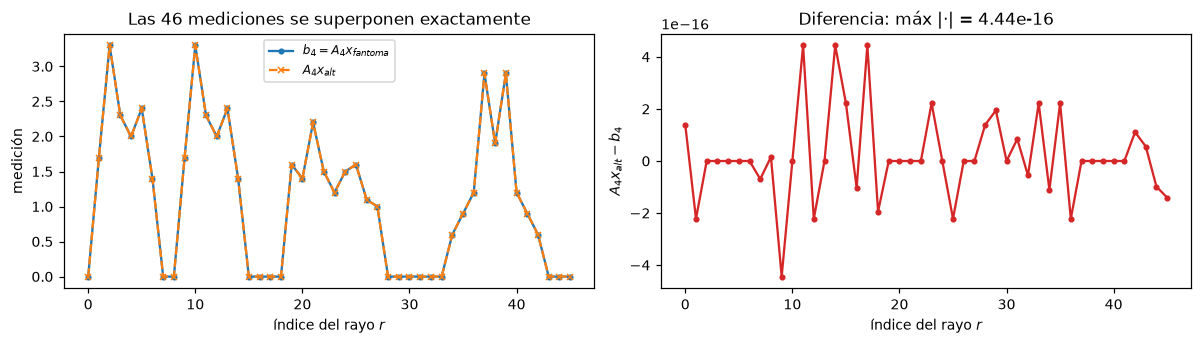

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.2))

axes[0].plot(b4, "o-", ms=3, label=r"$b_4 = A_4 x_{fantoma}$")
axes[0].plot(b4_alt, "x--", ms=4, label=r"$A_4 x_{alt}$")
axes[0].set_xlabel("índice del rayo $r$")
axes[0].set_ylabel("medición")
axes[0].set_title("Las 46 mediciones se superponen exactamente")
axes[0].legend(fontsize=8)

axes[1].plot(b4_alt - b4, "o-", ms=3, color="tab:red")
axes[1].set_xlabel("índice del rayo $r$")
axes[1].set_ylabel(r"$A_4 x_{alt} - b_4$")
axes[1].set_title(f"Diferencia: máx |·| = {np.abs(b4_alt - b4).max():.2e}")

fig.tight_layout()
guardar(fig, "ejercicio_04c_mediciones_iguales")
plt.show()

### ¿Qué información de la imagen es invisible para $A_4$?

Cualquier componente de la imagen que viva en $\operatorname{Nul}(A_4)$ —un subespacio de
dimensión $25$— es completamente invisible. La estructura de esos "fantasmas" se entiende
mirando qué mide $A_4$: sumas a lo largo de filas, columnas y las dos familias de
diagonales. Un patrón que sume **cero** simultáneamente sobre toda fila, toda columna y
toda diagonal no altera ninguna medición, y por lo tanto es indistinguible de la imagen
nula. Estos patrones son necesariamente alternados en signo y de media cero: no pueden
tener una zona "toda clara" o "toda oscura", porque eso cambiaría alguna suma.

Visualizamos una base ortonormal del espacio nulo para ver ese tipo de estructura.

dim Nul(A4) = 25
máx ||A4 v_i|| sobre la base: 8.326672684688674e-16


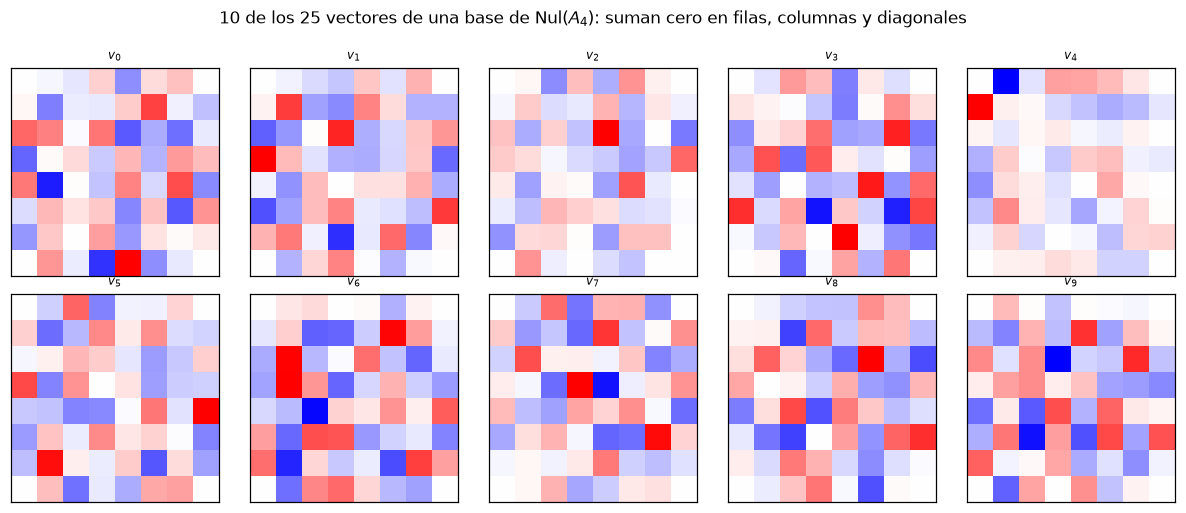

In [10]:
rango_A4 = np.linalg.matrix_rank(A4)
base_nulo = Vt[rango_A4:]          # 25 vectores ortonormales que generan Nul(A4)
print("dim Nul(A4) =", base_nulo.shape[0])
print("máx ||A4 v_i|| sobre la base:", np.abs(A4 @ base_nulo.T).max())

fig, axes = plt.subplots(2, 5, figsize=(11.0, 4.6))
for idx, ax in enumerate(axes.ravel()):
    W = base_nulo[idx].reshape(n, n)
    lim = np.abs(W).max()
    ax.imshow(W, cmap="bwr", vmin=-lim, vmax=lim)
    ax.set_title(f"$v_{{{idx}}}$", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(r"10 de los 25 vectores de una base de $\mathrm{Nul}(A_4)$: "
             r"suman cero en filas, columnas y diagonales", y=1.0)
fig.tight_layout()
guardar(fig, "ejercicio_04c_base_nulo")
plt.show()

Para hacerlo todavía más concreto, exhibimos un elemento **explícito y entero** del espacio
nulo: un patrón de $\pm1$ soportado en un bloque de $4\times4$ píxeles,

$$P = \begin{pmatrix}
0 & -1 & 1 & 0\\
1 & 0 & 0 & -1\\
-1 & 0 & 0 & 1\\
0 & 1 & -1 & 0
\end{pmatrix},$$

que suma cero en cada fila, en cada columna y en cada una de las diagonales que tocan sus
ocho entradas no nulas.

In [11]:
P = np.array([[0, -1,  1,  0],
              [1,  0,  0, -1],
              [-1, 0,  0,  1],
              [0,  1, -1,  0]], dtype=float)

W = np.zeros((n, n))
W[2:6, 2:6] = P          # lo colocamos en el centro de la imagen
w = W.reshape(-1)

print("patrón propuesto (8x8):")
print(W.astype(int))
print()
print("suma por filas     :", W.sum(axis=1))
print("suma por columnas  :", W.sum(axis=0))
i_idx, j_idx = np.nonzero(W)
for nombre, clave in [("diagonales i+j", i_idx + j_idx), ("diagonales i-j", i_idx - j_idx)]:
    sumas = {int(s): float(W[i_idx[clave == s], j_idx[clave == s]].sum())
             for s in np.unique(clave)}
    print(f"suma por {nombre}: {sumas}")
print()
print("||A2 w|| =", np.linalg.norm(A2 @ w))
print("||A4 w|| =", np.linalg.norm(A4 @ w), "   <- invisible para A4")
print("||A7 w|| =", round(float(np.linalg.norm(A7 @ w)), 6), "   <- A7 SÍ lo ve")

patrón propuesto (8x8):
[[ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0 -1  1  0  0  0]
 [ 0  0  1  0  0 -1  0  0]
 [ 0  0 -1  0  0  1  0  0]
 [ 0  0  0  1 -1  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]]

suma por filas     : [0. 0. 0. 0. 0. 0. 0. 0.]
suma por columnas  : [0. 0. 0. 0. 0. 0. 0. 0.]
suma por diagonales i+j: {5: 0.0, 6: 0.0, 8: 0.0, 9: 0.0}
suma por diagonales i-j: {-2: 0.0, -1: 0.0, 1: 0.0, 2: 0.0}

||A2 w|| = 0.0
||A4 w|| = 0.0    <- invisible para A4
||A7 w|| = 5.830952    <- A7 SÍ lo ve


El último cálculo cierra el ejercicio: ese patrón de $\pm1$ es indistinguible del vector
nulo para $A_2$ y $A_4$, pero **no** para $A_7$. Las direcciones adicionales $(2,1)$, $(1,2)$ y
$(3,1)$ atraviesan la grilla con pendientes que rompen la simetría de las filas, columnas y
diagonales, y por eso llevan el rango de $39$ a $64$.

**Conclusión.** La unicidad de la reconstrucción no depende de cuántas mediciones tomamos,
sino de cuántas son *independientes*. Con $A_2$ y $A_4$ existen infinitas imágenes
compatibles con los datos y el problema está mal planteado; con $A_7$ hay una única solución
exacta. En el Ejercicio 5 vamos a ver el efecto concreto de esto sobre las reconstrucciones,
y en el Ejercicio 6 comprobaremos que rango completo garantiza unicidad pero **no**
estabilidad frente al ruido.